# Baseline model: predicting job satisfaction with logistic regression
**Data:** NSCG 2023 respondents linked to O*NET work values (`nscg2023_onet30_2_subset.csv`).

**Goal:** a baseline that uses *background factors only*. The person-job fit features (`FAC*` = what the person values, `ONET_WV_*` = what the occupation offers) are deliberately held out so we can measure in November how much fit adds.

**Evaluation:** 5-fold `StratifiedGroupKFold` grouped by occupation, ROC AUC and PR AUC with occupation-level bootstrap confidence intervals.

In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (roc_auc_score, average_precision_score, precision_score,
                             recall_score, f1_score, confusion_matrix, roc_curve)
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

SEED = 42
DATA_PATH = "nscg2023_onet30_2_subset.csv"   # change if the file lives elsewhere

## 1. Load data and define the target
`JOBSATIS` is coded 1 = very satisfied, 2 = somewhat satisfied, 3 = somewhat dissatisfied, 4 = very dissatisfied (verify against the NSCG codebook). We use a binary target: **satisfied = 1** (codes 1 or 2).

In [2]:
df = pd.read_csv(DATA_PATH, low_memory=False)
print("shape:", df.shape, "| missing values:", int(df.isna().sum().sum()))
print(df["JOBSATIS"].value_counts().sort_index().to_dict())

y = df["JOBSATIS"].isin([1, 2]).astype(int).values   # 1 = satisfied
groups = df["SOC2018_CODE"].values                    # one group per occupation
print(f"satisfied: {y.mean():.1%} | unsatisfied: {1 - y.mean():.1%} | occupations: {len(np.unique(groups))}")

shape: (6849, 42) | missing values: 0
{1: 3012, 2: 3218, 3: 511, 4: 108}
satisfied: 91.0% | unsatisfied: 9.0% | occupations: 25


## 2. Choose baseline features
- **Demographics:** age, sex, degree level
- **Work context:** how related the job is to the degree, whether the person supervises, primary work activity

Excluded on purpose: `FAC*` and `ONET_WV_*` (fit features), occupation codes (used only as CV groups), and `WTSURVY` (survey weight).

In [3]:
NUM = ["AGE"]
CAT_DEMO = ["SEX_2023", "DGRDG"]
CAT_WORK = ["OCEDRLP", "SUPWK", "WAPRI"]
FEATURE_SETS = {
    "demographics_only": NUM + CAT_DEMO,
    "background_full":   NUM + CAT_DEMO + CAT_WORK,
}

# guard: no fit features may leak into the baseline
for cols in FEATURE_SETS.values():
    assert not any(c.startswith(("FAC", "ONET_WV")) for c in cols)

def make_pipe(cols):
    cat = [c for c in cols if c not in NUM]
    pre = ColumnTransformer([("num", StandardScaler(), [c for c in cols if c in NUM]),
                             ("cat", OneHotEncoder(handle_unknown="ignore"), cat)])
    return Pipeline([("pre", pre),
                     ("clf", LogisticRegression(class_weight="balanced", max_iter=2000))])

## 3. Cross-validation folds
Grouping by occupation keeps every occupation entirely in train or test, so scores reflect performance on *unseen occupations*. Folds are saved so the November fit-feature models can reuse the **exact same splits**.

In [4]:
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
folds = list(cv.split(df, y, groups))

fold_id = np.empty(len(df), dtype=int)
for k, (_, te) in enumerate(folds):
    fold_id[te] = k
pd.DataFrame({"OBSNUM": df["OBSNUM"], "fold": fold_id}).to_csv("folds.csv", index=False)

print("fold sizes:      ", [len(te) for _, te in folds])
print("unsatisfied/fold:", [int((1 - y[te]).sum()) for _, te in folds])

fold sizes:       [1450, 1321, 1289, 1398, 1391]
unsatisfied/fold: [114, 125, 140, 115, 125]


## 4. Metrics
The unsatisfied group is the small class, so we report ROC AUC, PR AUC for the unsatisfied class, and precision/recall/F1 for that class at a 0.5 threshold. The confidence interval resamples **occupations** (not people), since people in the same occupation are not independent.

In [5]:
def oof_predict(model_fn, cols):
    """Out-of-fold P(satisfied) for every respondent."""
    p = np.zeros(len(df))
    for tr, te in folds:
        m = model_fn(cols)
        m.fit(df.iloc[tr][cols], y[tr])
        p[te] = m.predict_proba(df.iloc[te][cols])[:, 1]
    return p

def metrics(y, p, thr=0.5):
    pu, yu, pred_u = 1 - p, 1 - y, (p < thr).astype(int)    # unsatisfied = positive class
    return {"roc_auc": roc_auc_score(y, p),
            "pr_auc_unsat": average_precision_score(yu, pu),
            "precision_unsat": precision_score(yu, pred_u, zero_division=0),
            "recall_unsat": recall_score(yu, pred_u),
            "f1_unsat": f1_score(yu, pred_u)}

def cluster_boot_ci(y, p, groups, n=1000, seed=SEED):
    rng = np.random.default_rng(seed)
    ug = np.unique(groups)
    idx = {g: np.where(groups == g)[0] for g in ug}
    out = []
    for _ in range(n):
        ii = np.concatenate([idx[g] for g in rng.choice(ug, len(ug))])
        if len(np.unique(y[ii])) == 2:
            out.append(roc_auc_score(y[ii], p[ii]))
    return np.percentile(out, [2.5, 97.5])

## 5. Fit and compare models
A dummy model (predicts the class prior) is the floor. Note its *pooled* AUC can fall below 0.5 because the prior differs slightly by fold; its per-fold AUC is exactly 0.5.

In [6]:
rows, preds = [], {"OBSNUM": df["OBSNUM"], "y_satisfied": y, "fold": fold_id}
dummy = lambda cols: DummyClassifier(strategy="prior")
specs = [("dummy_prior", dummy, NUM)] + [(f"logreg_{k}", make_pipe, v) for k, v in FEATURE_SETS.items()]

for name, fn, cols in specs:
    p = oof_predict(fn, cols)
    preds[name] = p
    r = {"model": name, **metrics(y, p)}
    r["auc_ci_low"], r["auc_ci_high"] = (cluster_boot_ci(y, p, groups) if name != "dummy_prior" else (np.nan, np.nan))
    fold_aucs = [roc_auc_score(y[te], p[te]) for _, te in folds]
    r["fold_auc_mean"], r["fold_auc_sd"] = np.mean(fold_aucs), np.std(fold_aucs)
    rows.append(r)

results = pd.DataFrame(rows).round(3)
results.to_csv("baseline_results.csv", index=False)
pd.DataFrame(preds).to_csv("oof_predictions.csv", index=False)
results

,model,roc_auc,pr_auc_unsat,precision_unsat,recall_unsat,f1_unsat,auc_ci_low,auc_ci_high,fold_auc_mean,fold_auc_sd
0,dummy_prior,0.465,0.084,0.000,0.000,0.000,NaN,NaN,0.500,0.000
1,logreg_demographics_only,0.553,0.102,0.102,0.593,0.174,0.530,0.578,0.558,0.029
2,logreg_background_full,0.577,0.120,0.113,0.512,0.185,0.549,0.606,0.577,0.033


## 6. ROC curves (out-of-fold)

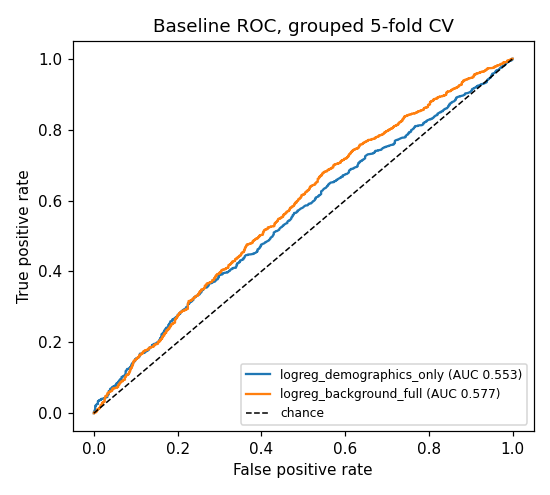

In [7]:
fig, ax = plt.subplots(figsize=(5, 4.5))
for name in ["logreg_demographics_only", "logreg_background_full"]:
    fpr, tpr, _ = roc_curve(y, preds[name])
    ax.plot(fpr, tpr, label=f"{name} (AUC {roc_auc_score(y, preds[name]):.3f})")
ax.plot([0, 1], [0, 1], "k--", lw=1, label="chance")
ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate")
ax.set_title("Baseline ROC, grouped 5-fold CV"); ax.legend(fontsize=8, loc="lower right")
plt.tight_layout(); plt.show()

## 7. Error types and which features matter
The confusion matrix uses the full baseline at a 0.5 threshold. Odds ratios come from a fit on all data and are for **interpretation only**, not evaluation.

In [8]:
best = "logreg_background_full"
cm = confusion_matrix(y, (preds[best] >= 0.5).astype(int))
print(pd.DataFrame(cm, index=["true unsatisfied", "true satisfied"],
                   columns=["pred unsatisfied", "pred satisfied"]))

cols = FEATURE_SETS["background_full"]
m = make_pipe(cols).fit(df[cols], y)
odds = pd.DataFrame({"feature": m.named_steps["pre"].get_feature_names_out(),
                     "odds_ratio": np.exp(m.named_steps["clf"].coef_[0])}).round(3)
odds.to_csv("odds_ratios.csv", index=False)
print("\nLargest effects (odds ratio of being satisfied):")
print(odds.assign(abs_log=np.abs(np.log(odds.odds_ratio))).sort_values("abs_log", ascending=False)
          .head(8).drop(columns="abs_log").to_string(index=False))

                  pred unsatisfied  pred satisfied
true unsatisfied               317             302
true satisfied                2494            3736

Largest effects (odds ratio of being satisfied):
       feature  odds_ratio
cat__OCEDRLP_3       0.619
 cat__WAPRI_11       1.483
cat__OCEDRLP_1       1.449
 cat__WAPRI_10       1.421
 cat__WAPRI_13       0.707
 cat__WAPRI_12       0.735
  cat__WAPRI_7       1.332
  cat__WAPRI_2       0.803


## 8. Takeaways and next steps
- The background-only baseline has modest predictive power (AUC about 0.58). Demographics alone are about 0.55, and the work-context features add a small, not clearly significant, amount (the CIs overlap).
- Only 25 occupations are in this file, so intervals are wide and occupation-level features (O*NET) will take only 25 distinct values.
- **November:** add the fit features (person's `FAC*` values vs. the occupation's `ONET_WV_*`) and reuse `folds.csv`. Compare AUC on identical splits and bootstrap the paired AUC difference by occupation.
- Optional: use `WTSURVY` for weighted metrics, and try tree models/KNN on the same folds.